In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import numpy as np
import matplotlib.animation as animation
import matplotlib.gridspec as gridspec
import pandas as pd
from datetime import datetime, timedelta
import matplotlib.dates as mdates
import os
import urllib.request
import random
from scipy.optimize import curve_fit
from scipy.interpolate import interp1d
from numpy import trapezoid
from scipy.signal import argrelmin
import seaborn as sns
import math
from VerticalModelFunction_Copy1 import model as VerticalModel
import datetime
from SingleDayDataImporter_Copy1 import Import_NOAA_Data as NOAA




7


Text(0.5, 1.0, 'Year: 25 | Day: 360 | Energy: 4.47 | Sky Coverage: 7/8')

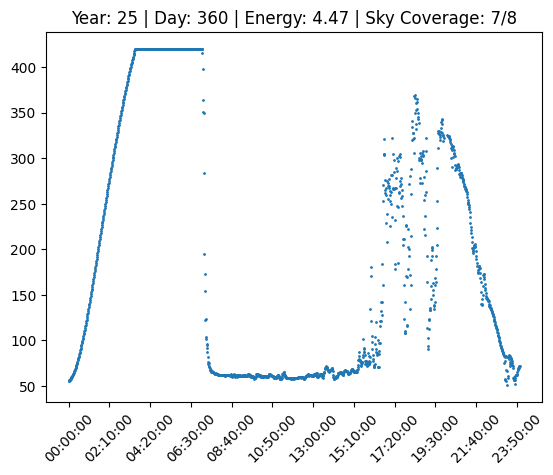

In [11]:

#                                                 V--thiss
december_2025_sky_coverage = [2,7,6,7,3,3,2,2,1,0,3,7,1,2,5,4,6,4,2,5,3,5,6,2,3,7,7,4,0,2,7]

year = 25
day = 360

if (year == 25) & (335 <= day <= 365):
    # we are in december
    cloud_level = december_2025_sky_coverage[day - 335]

print(cloud_level)


direct_irradiance, diffuse_irradiance, upwelling_irradiance, NOAA_time, zeniths = NOAA(year, day)

zenith = np.nanmean(zeniths)
effs = [0.24699832280882955, 0.03850296370170911, 0.05890744297245301]
simulated_power = VerticalModel(direct_irradiance, diffuse_irradiance, upwelling_irradiance, effs, 50, zenith, 0)

NOAA_time = NOAA_time.to_numpy()
energy = trapezoid(np.nan_to_num(simulated_power,nan = 0),dx=60)/(1000*60**2)

N = 12

plt.scatter(NOAA_time, simulated_power, s = 1)
plt.xticks(ticks = NOAA_time[::int(len(NOAA_time)/(N-1))], rotation = 45)


plt.title(fr'Year: {year} | Day: {day} | Energy: {np.round(energy,2)} | Sky Coverage: {cloud_level}/8')







31
31


(0.0, 7.0)

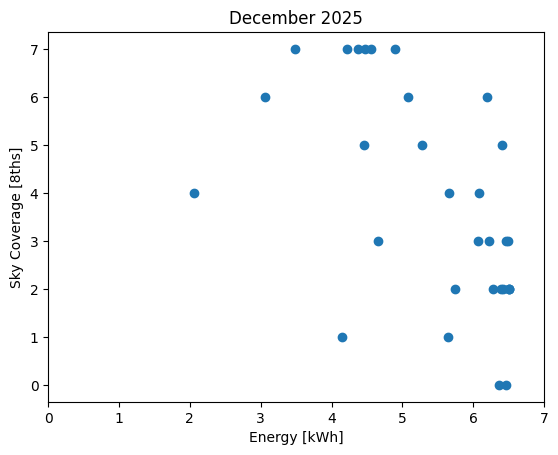

In [12]:


#                                                 V--thiss
december_2025_sky_coverage = [2,7,6,7,3,3,2,2,1,0,3,7,1,2,5,4,6,4,2,5,3,5,6,2,3,7,7,4,0,2,7]

year = 25
# day = 344


december_day_range = np.arange(335, 366,1)

energies = []

for day in december_day_range:
    if (year == 25) & (335 <= day <= 365):
        # we are in december
        cloud_level = december_2025_sky_coverage[day - 335]
    
    # print(cloud_level)
    
    
    direct_irradiance, diffuse_irradiance, upwelling_irradiance, NOAA_time, zeniths = NOAA(year, day)
    
    zenith = np.nanmean(zeniths)
    effs = [0.24699832280882955, 0.03850296370170911, 0.05890744297245301]
    simulated_power = VerticalModel(direct_irradiance, diffuse_irradiance, upwelling_irradiance, effs, 50, zenith, 0)
    
    NOAA_time = NOAA_time.to_numpy()
    energy = trapezoid(np.nan_to_num(simulated_power,nan = 0),dx=60)/(1000*60**2)
    energies.append(energy)
print(len(energies))
print(len(december_2025_sky_coverage))
plt.scatter(energies, december_2025_sky_coverage)
plt.xlabel('Energy [kWh]')
plt.ylabel('Sky Coverage [8ths]')

plt.title('December 2025')

plt.xlim(0,7)



